# Reconstruction — one slice, several slices, and why the center matters

Generates a phantom with a known center-of-rotation deviation, normalizes it, and reconstructs through the `algotom_fbp` backend -- first a single slice with the wrong (nominal) center versus the correct one, to make concrete why calibration matters, then a stack of several slices at once through the exact same `reconstruct()` call.

In [1]:
import sys
from pathlib import Path

here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "data_import").is_dir())
sys.path.insert(0, str(project_root))

print("Using project root:", project_root)

Using project root: D:\GitHub\Universial-Reconstructions - Copy\.claude\worktrees\code-package-review-13feda


## 1. Generate a phantom

A real center-of-rotation deviation injected (3 px), no tilt and no detector defects this time -- this notebook is about reconstruction itself, not about the artifacts `preprocessing` already has its own demo for.

In [2]:
from tests.fixtures.realistic_phantom import generate, to_project_object

TRUE_COR = 8.0  # pixels -- large enough that the artifact is clearly visible, not just measurable

phantom = generate(
    shape=(12, 96, 96), n_angles=300,
    cor_deviation=TRUE_COR, tilt_deg=0.0,
    n_scratches=0, n_defective_pixels=0, inhomogeneity_strength=0.0,
    noise_level=0.0, seed=1,
)
print("volume shape:", phantom.volume.shape)
print("true_center_of_rotation:", phantom.true_center_of_rotation, "px")

volume shape: (12, 96, 96)
true_center_of_rotation: 8.0 px


## 2. Project object and normalization

In [3]:
from preprocessing import build_reference, normalize_rows

project = to_project_object(phantom)
reference = build_reference(project)
normalized = normalize_rows(project, slice(None), reference)

print(project)
print("normalized shape:", normalized.shape)

ProjectObject(format=hdf5, storage_mode=ram, vendor=generic_parallel_synchrotron_hdf5, handles=['projections', 'flats', 'darks'])
normalized shape: (300, 12, 96)


## 3. Reconstruct one slice — wrong center vs. correct center

`reconstruct()` takes a single 2D sinogram and returns a single 2D image -- no project object involved, just the array `normalize_rows()` already produced, plus angles/center/geometry prepared here. Trying the nominal (geometric) center first, ignoring the known deviation, exactly the mistake calibration exists to catch.

In [4]:
from reconstruction import Geometry, reconstruct

row = phantom.volume.shape[0] // 2
sinogram = normalized[:, row, :]
width = sinogram.shape[1]
geometry = Geometry(geometry_type="parallel")

nominal_center = width / 2
correct_center = width / 2 + TRUE_COR   # verified sign: nominal + true_cor, not minus

image_wrong = reconstruct(sinogram, phantom.angles, center=nominal_center, geometry=geometry, backend="algotom_fbp")
image_right = reconstruct(sinogram, phantom.angles, center=correct_center, geometry=geometry, backend="algotom_fbp")

print("image_wrong shape:", image_wrong.shape)
print("image_right shape:", image_right.shape)

C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


image_wrong shape: (96, 96)
image_right shape: (96, 96)


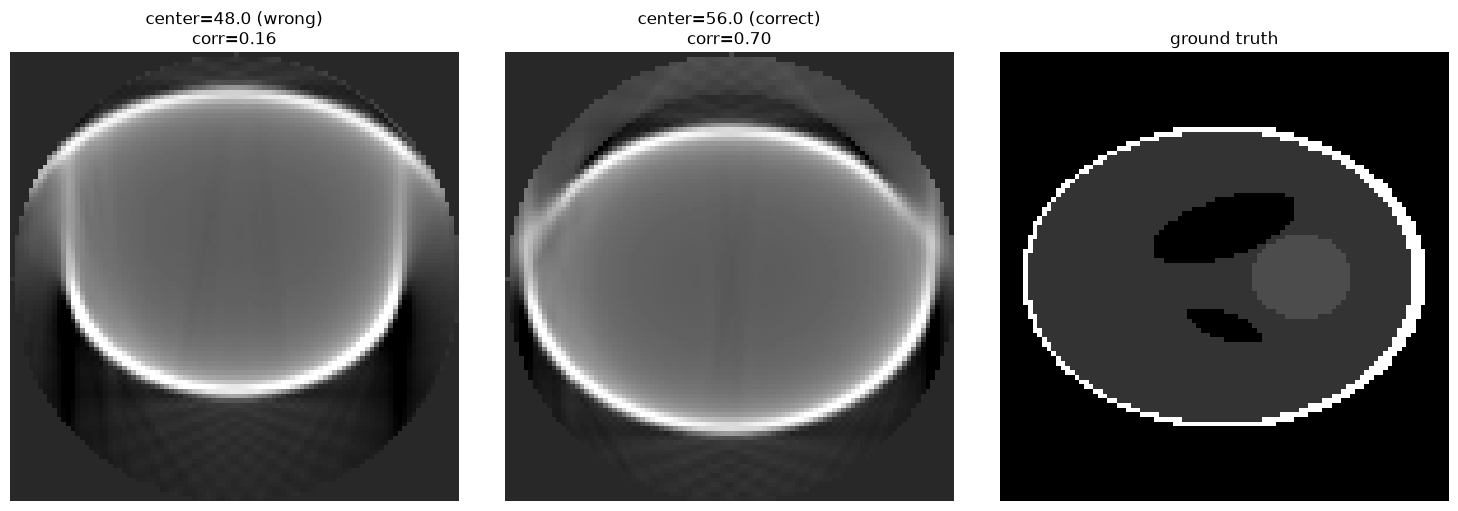

In [5]:
import numpy as np
import matplotlib.pyplot as plt


def corr(a, b):
    return np.corrcoef(a.ravel(), b.ravel())[0, 1]


ground_truth = phantom.volume[row]

# shared contrast scale across both reconstructions, so the comparison
# isn't hidden by imshow auto-scaling each panel to its own range
vmin, vmax = np.percentile(np.concatenate([image_wrong.ravel(), image_right.ravel()]), [1, 99])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_wrong, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title(f"center={nominal_center} (wrong)\ncorr={corr(image_wrong, ground_truth):.2f}")
axes[1].imshow(image_right, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title(f"center={correct_center} (correct)\ncorr={corr(image_right, ground_truth):.2f}")
axes[2].imshow(ground_truth, cmap="gray")
axes[2].set_title("ground truth")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The wrong-center reconstruction is visibly off-axis -- the object sits shifted and asymmetrically cropped within the field of view, with a visible vertical seam artifact, instead of the properly centered, symmetric boundary the corrected one recovers. The correlation gap (0.16 vs. 0.70) confirms it's not just a subjective impression. Neither panel is as crisp as the ground truth; that residual gap is the same real, separately-verified FBP/Gibbs-ringing ceiling from `tests/test_reconstruction.py` (this phantom, this resolution, tops out around 0.7-0.8 even with a perfectly correct center) -- the wrong-vs-correct comparison here is about the *additional* damage a bad center does on top of that baseline, not a claim that the corrected reconstruction is pixel-perfect.

## 4. Units: "per pixel" vs. real attenuation coefficients

`geometry` above was built with no `detector_pixel_size` -- so `image_right`'s values are attenuation coefficients in **"per pixel"** units: whatever the FBP math naturally produces assuming unit pixel spacing, not tied to any real physical length. That's what every reconstruction in this notebook has been using so far.

Give `Geometry` a real `detector_pixel_size` (this project always stores it in micrometers) and `reconstruct()` automatically converts its output to real attenuation, in inverse micrometers (1/um) -- dividing by the pixel size, since the raw FBP output is `mu * pixel_size`, not `mu` itself. There's no setting to choose the unit; it's determined entirely by whether a pixel size is known. See [`RECONSTRUCTION.md`](../RECONSTRUCTION.md)'s "Units" section for the full reasoning.

The cell below reconstructs the *same* sinogram a second time with the pixel size set, rather than just dividing `image_right` by hand, so it's exercising the real code path -- but that means it re-runs `algotom`'s FBP algorithm itself, which (confirmed directly, independently of this feature) isn't perfectly bit-reproducible between separate calls on its CPU fallback path -- two calls with identical arguments differ by roughly 1-2%. So the printed ratio below is only *approximately*, not exactly, `detector_pixel_size` -- the small residual is that backend-level floating-point noise, not an error in the conversion. The conversion itself is an exact division; `tests/test_reconstruction.py` checks that precisely, against a deterministic hand-written backend where there's no such noise to contend with.

In [6]:
detector_pixel_size_um = 2.5  # a plausible synchrotron detector pixel pitch, purely illustrative here
geometry_um = Geometry(geometry_type="parallel", detector_pixel_size=detector_pixel_size_um)

image_right_um = reconstruct(sinogram, phantom.angles, center=correct_center, geometry=geometry_um, backend="algotom_fbp")

print("peak value, per-pixel units (no detector_pixel_size):", image_right.max(), "1/px")
print("peak value, real attenuation units (detector_pixel_size=2.5um):", image_right_um.max(), "1/um")
print("ratio:", image_right.max() / image_right_um.max(), "(expected close to, not exactly,", detector_pixel_size_um, "-- see markdown above)")
print("dtype:", image_right_um.dtype)

peak value, per-pixel units (no detector_pixel_size): 0.8440017 1/px
peak value, real attenuation units (detector_pixel_size=2.5um): 0.33760065 1/um
ratio: 2.5000002 (expected close to, not exactly, 2.5 -- see markdown above)
dtype: float32


C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


## 5. Reconstruct several slices at once

Same `reconstruct()` call, same correct center -- just handed a stack of sinograms instead of one. No separate function, no loop written here: `sinogram` being 3D instead of 2D is the only difference, and the return shape follows it.

`normalized` -- from `normalize_rows()` a couple cells up -- is a plain numpy array, `(n_angles, height, width)`: the same shape/axis convention as every projection array in this codebase (angle first). Slicing several rows out of it with `normalized[:, rows, :]` keeps that same angle-first convention, `(n_angles, len(rows), width)` -- and that's exactly the shape `reconstruct()` expects for a stack, so it can be handed over directly, no reshaping.

In [7]:
rows = [4, 5, 6, 7, 8]  # solidly inside the phantom's height extent -- see doc/REALISTIC_PHANTOM.md
sinogram_stack = normalized[:, rows, :]        # (n_angles, len(rows), width) -- reconstruct()'s expected input shape, as-is

images = reconstruct(sinogram_stack, phantom.angles, center=correct_center, geometry=geometry, backend="algotom_fbp")
print("input stack shape:", sinogram_stack.shape)
print("output stack shape:", images.shape)  # (n_slices, height, width) -- reconstructed images, not sinograms, so slice-first

input stack shape: (300, 5, 96)
output stack shape: (5, 96, 96)


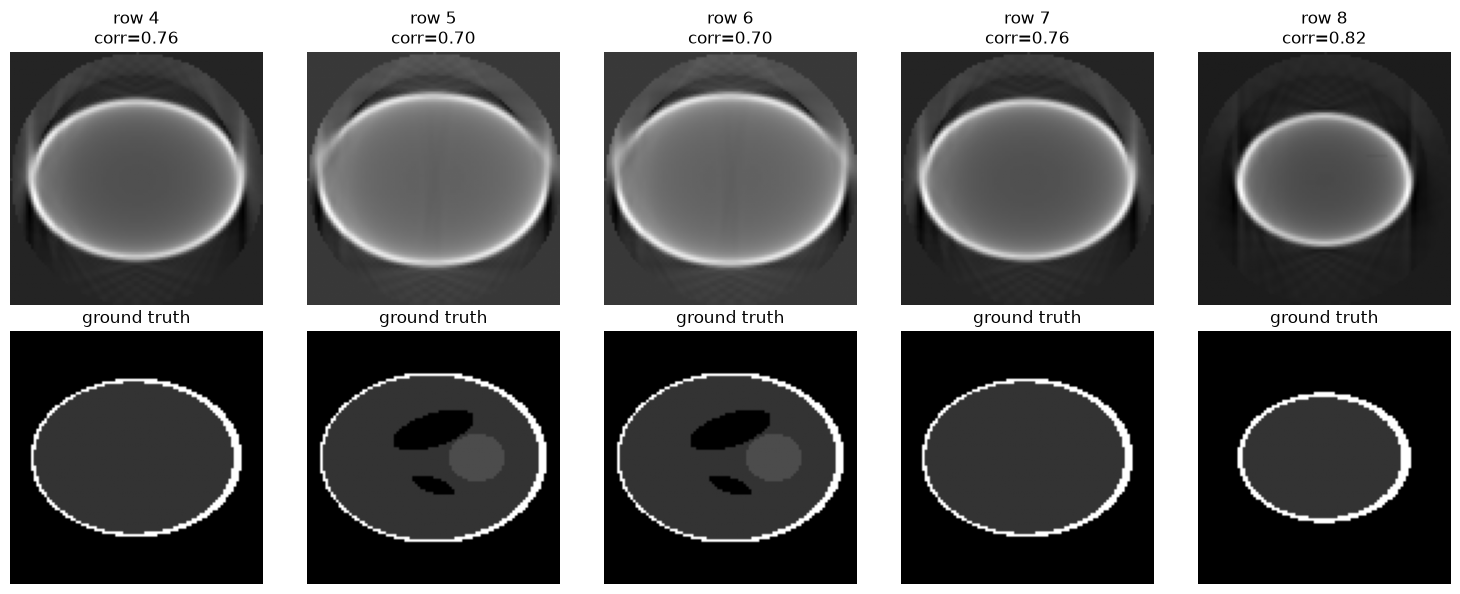

In [8]:
fig, axes = plt.subplots(2, len(rows), figsize=(3 * len(rows), 6))
for col, r in enumerate(rows):
    axes[0, col].imshow(images[col], cmap="gray")
    axes[0, col].set_title(f"row {r}\ncorr={corr(images[col], phantom.volume[r]):.2f}")
    axes[1, col].imshow(phantom.volume[r], cmap="gray")
    axes[1, col].set_title("ground truth")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

Every slice lands in roughly the same correlation range -- consistent, not a fluke of the one row picked earlier. The phantom's cross-section changes shape row to row (it's a genuine 3D object, not a repeated 2D slice -- see `doc/REALISTIC_PHANTOM.md`), and the reconstruction tracks that correctly at every height.

## Recap

```
generate() -> PhantomProject -> to_project_object() -> ProjectObject
                                        |
                          build_reference() + normalize_rows() -> normalized sinograms
                                        |
                     reconstruct(sinogram_or_stack, angles, center, geometry, backend="algotom_fbp")
                                        |
                     float32 attenuation coefficients, 1/um if geometry.detector_pixel_size
                     is set, otherwise "per pixel" -- see doc/RECONSTRUCTION.md's Units section
```

The wrong-vs-correct-center comparison above is exactly the problem calibration (not built yet) exists to solve automatically -- search over candidate centers, score each reconstruction, pick the best, using this same `reconstruct()` call as its evaluation primitive. See [`ARCHITECTURE.md`](../ARCHITECTURE.md) for how the pieces fit together, and `tests/test_reconstruction.py` for the backend contract's own test coverage.